# Le vrai prix de la ville : mesurer l'effet de la distance

Le notebook d'exploration décrit les prix par tranche de distance. Ici, on cherche à mesurer l'effet de la distance sur le prix au m², uniquement avec des calculs simples sur les données observées : corrélations, différences de médianes, comparaisons entre ventes comparables afin d'éviter toute modélisation

## 1. Principe

Comparer directement les prix près et loin des stations est trompeur : les stations sont plus nombreuses dans les communes chères. On neutralise donc le lieu et la taille du logement par construction, sans modèle :

- le prix relatif d'une vente est son écart (en %) au prix médian de sa commune la même année ;
- une cellule regroupe les ventes d'une même commune, d'une même année et d'une même classe de surface (moins de 30 m², 30-50, 50-80, plus de 80). Dans une cellule, on compare des biens comparables, seule la distance à la station change ;
- les résultats de toutes les cellules sont ensuite résumés (moyenne pondérée par le nombre de ventes, médiane, part de cellules où l'écart est positif).

Les 1 % de prix les plus bas et les plus hauts de chaque zone sont écartés.

In [1]:
import pandas as pd

from vrai_prix import analysis as A
from vrai_prix import visualization as V

V.style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
df = A.charger_donnees()
d = A.preparer(df)
print(f"{len(d):,} ventes utilisées sur {len(df):,}".replace(",", " "))

313 546 ventes utilisées sur 319 947


## 2. Corrélation entre distance et prix

La corrélation de Spearman compare les rangs (moins sensible aux valeurs extrêmes), celle de Pearson mesure une liaison linéaire. Une valeur négative veut dire que le prix baisse quand la distance augmente ; elle va de −1 à 1, et une valeur proche de 0 indique une liaison faible.

On la calcule sur le prix brut puis sur le prix relatif à la commune : la différence entre les deux montre ce qui vient du lieu.

In [3]:
A.sauver(A.correlations(d), "correlations_distance_prix.csv", index=False)

,zone,n,spearman_prix,pearson_prix,spearman_prix_relatif,pearson_prix_relatif
0,Ensemble,313546,-0.57,-0.46,-0.04,-0.04
1,Paris,140376,-0.05,-0.06,-0.01,-0.02
2,Petite couronne,173170,-0.25,-0.23,-0.06,-0.04


In [4]:
A.sauver(A.correlations(d, par="annee"), "correlations_par_annee.csv", index=False)

,zone,n,annee,spearman_prix,pearson_prix,spearman_prix_relatif,pearson_prix_relatif
0,Ensemble,70246,2021,-0.60,-0.49,-0.04,-0.03
1,Ensemble,73307,2022,-0.58,-0.48,-0.04,-0.04
2,Ensemble,57675,2023,-0.57,-0.47,-0.04,-0.03
3,Ensemble,51281,2024,-0.56,-0.45,-0.04,-0.03
4,Ensemble,61037,2025,-0.56,-0.45,-0.04,-0.04
5,Paris,29869,2021,-0.05,-0.06,-0.02,-0.02
6,Paris,32496,2022,-0.05,-0.05,-0.01,-0.02
7,Paris,26315,2023,-0.05,-0.06,-0.02,-0.02
8,Paris,23909,2024,-0.06,-0.07,-0.02,-0.02
9,Paris,27787,2025,-0.05,-0.06,-0.00,-0.01


Pris ensemble, le prix et la distance sont nettement corrélés négativement (Spearman autour de −0,56 à −0,60, Pearson autour de −0,45 à −0,49 selon l'année). Mais cette corrélation vient surtout de la différence entre Paris et la petite couronne : Paris est plus cher et ses ventes sont plus proches des stations. Dans chaque zone, elle est bien plus faible : environ −0,05 à −0,06 à Paris et −0,24 à −0,27 en petite couronne (Spearman, prix brut).

En passant du prix brut au prix relatif à la commune, la corrélation tombe presque à zéro partout (entre 0 et −0,06). À l'intérieur d'une même commune, la distance à la station explique donc très peu les écarts de prix entre appartements.

Les valeurs sont stables d'une année à l'autre : on ne voit pas de changement net entre 2021 et 2025, sauf un léger recul de la corrélation d'ensemble (de −0,60 à −0,56).

Une corrélation faible ne veut pas dire qu'il n'y a aucun effet : elle mesure la liaison moyenne sur toutes les distances, alors que l'effet semble surtout apparaître au-delà de 500-600 m (voir les sections suivantes et le notebook d'exploration).

## 3. Variation du prix par tranche de 200 m

Prix médian dans chaque tranche de 200 m, et variation d'une tranche à la suivante, ramenée à 100 m. La colonne `variation_par_100m_eur` se lit : « 100 m plus loin, le prix médian change de x €/m² ». La colonne `variation_relatif_par_100m_pts` donne la même chose sur le prix relatif à la commune, en points de pourcentage.

,zone,tranche,n,prix_median,prix_relatif_median_pct,variation_eur,variation_pct,variation_par_100m_eur,variation_relatif_par_100m_pts
0,Paris,0-200,57341,"10,410.00",0.03,NaN,NaN,NaN,NaN
1,Paris,200-400,68168,"10,351.35",0.24,-58.65,-0.56,-29.32,0.11
2,Paris,400-600,13851,"9,864.86",-1.50,-486.49,-4.70,-243.24,-0.87
3,Paris,600-800,1016,"9,123.56",-5.07,-741.30,-7.51,-370.65,-1.79
4,Petite couronne,0-200,10896,"6,562.50",1.79,NaN,NaN,NaN,NaN
5,Petite couronne,200-400,30383,"6,346.15",2.14,-216.35,-3.30,-108.17,0.18
6,Petite couronne,400-600,32788,"6,120.77",0.97,-225.39,-3.55,-112.69,-0.58
7,Petite couronne,600-800,24435,"5,600.25",-1.17,-520.52,-8.50,-260.26,-1.07
8,Petite couronne,800-1000,18032,"5,222.22",-1.99,-378.03,-6.75,-189.01,-0.41
9,Petite couronne,1000-1200,13371,"4,951.47",0.00,-270.75,-5.18,-135.38,0.99


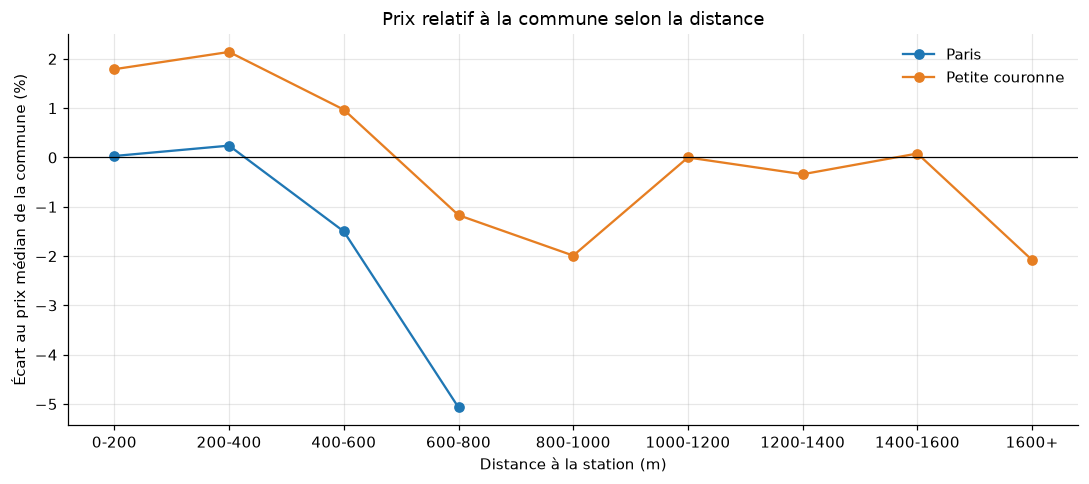

In [5]:
var = A.sauver(A.variation_par_tranche(d, largeur=200), "variation_par_tranche_200m.csv", index=False)
V.prix_relatif_tranches(var)
var

Dans les deux zones, le prix relatif à la commune est à peu près stable entre 0 et 400 m, avec un maximum dans la tranche 200-400 m (environ +0,2 % à Paris, +2 % en petite couronne). Il n'y a pas de baisse nette à très courte distance : la tranche 0-200 m est au même niveau que 200-400 m à Paris, et à peine en dessous en petite couronne (environ +1,8 % contre +2,1 %).

La baisse commence à partir de 400-600 m. À Paris, elle est forte : de −1,5 % à 400-600 m jusqu'à environ −5 % à 600-800 m. En petite couronne, elle est plus progressive : environ +1 % à 400-600 m, −1,2 % à 600-800 m, −2 % à 800-1000 m.

Au-delà de 1000 m, la courbe de la petite couronne remonte autour de zéro puis redescend à −2 % pour 1600 m et plus. Cette irrégularité est probablement due à la composition des ventes (peu de ventes et peu de communes à ces distances), et ne doit pas être lue comme un effet de la distance. À Paris, il n'y a pas de tranche au-delà de 800 m faute de ventes.

Les écarts restent petits (quelques points de pourcentage) : la distance à la station joue un rôle limité à l'intérieur d'une commune, et surtout au-delà de 400-600 m.

## 4. Écart à la tranche de référence, à biens comparables

Dans chaque cellule, on compare la médiane de chaque tranche à celle de la tranche 200-400 m, prise comme référence. La colonne `ecart_pct` est la moyenne pondérée sur les cellules. Les colonnes `ecart_median_cellules_pct` et `part_cellules_positives_%` indiquent si le résultat est partagé par la plupart des cellules ou tiré par quelques-unes.

,zone,tranche,ecart_pct,ecart_median_cellules_pct,part_cellules_positives_%,n_cellules,n_ventes
0,Paris,0-100,-0.88,-1.37,42.41,349.00,"13,907.00"
1,Paris,100-200,-0.25,-0.79,43.00,400.00,"43,071.00"
2,Paris,400-600,-1.80,-1.28,39.57,235.00,"13,517.00"
3,Paris,600-1000,-6.54,-3.60,33.33,39.00,581.00
4,Petite couronne,0-100,-3.54,-2.38,29.41,34.00,431.00
5,Petite couronne,100-200,-0.78,-0.01,49.83,293.00,"5,681.00"
6,Petite couronne,400-600,-0.92,-1.25,44.38,667.00,"25,997.00"
7,Petite couronne,600-1000,-3.03,-4.08,33.71,620.00,"27,193.00"


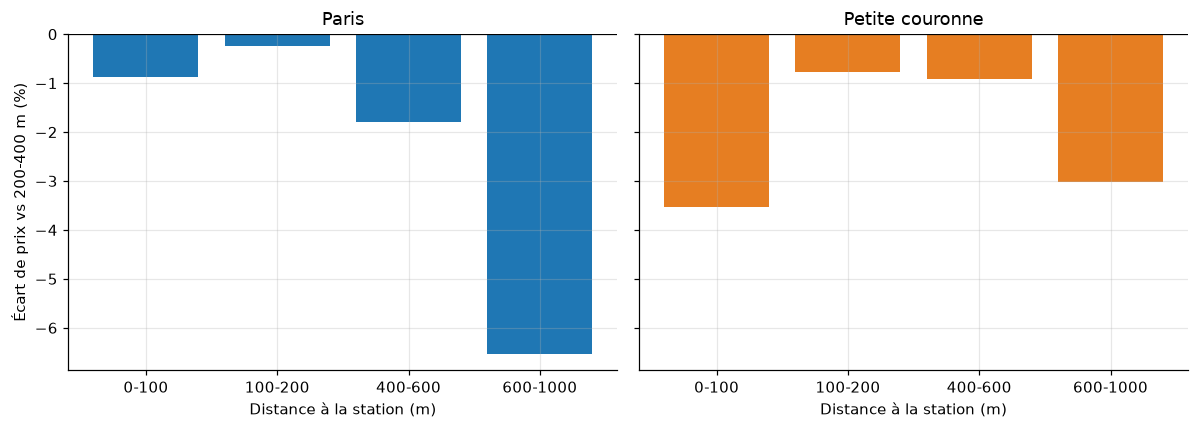

In [6]:
ecarts = A.sauver(A.ecarts_stratifies(d), "ecarts_stratifies.csv", index=False)
V.ecarts_stratifies_barres(ecarts)
ecarts

Toutes les tranches sont en dessous de la référence 200-400 m : à biens comparables, c'est donc dans cette tranche que le prix est le plus élevé, à Paris comme en petite couronne.

À moins de 100 m d'une station, l'écart est faible à Paris (environ −0,9 %) mais plus net en petite couronne (environ −3,5 %). Cela va dans le sens d'une décote de très courte distance (nuisances, bruit), à vérifier avec les effectifs : la tranche 0-100 m compte peu de ventes, et les coordonnées sont celles de la parcelle, ce qui ajoute du bruit à si courte distance. Entre 100 et 200 m, l'écart est faible dans les deux zones (environ −0,3 % à Paris, −0,8 % en petite couronne).

Au-delà de 400 m, la baisse s'accentue : environ −1,8 % à Paris et −0,9 % en petite couronne à 400-600 m, puis environ −6,5 % à Paris et −3 % en petite couronne à 600-1000 m. L'écart avec la distance est donc plus fort à Paris, où le réseau est dense et où s'éloigner de plus de 600 m signifie sortir d'un secteur très bien desservi.

Les deux zones ont ainsi un profil différent : à Paris, le prix ne baisse que quand on s'éloigne ; en petite couronne, il est aussi plus bas juste à côté de la station. Dans les deux cas, la distance la plus valorisée se situe entre 100 et 400 m. Les écarts restent de quelques points de pourcentage.

## 5. Prime de proximité : biens proches contre biens éloignés

Même méthode avec deux groupes : ventes à moins de 300 m d'une station contre ventes à plus de 600 m. La prime est `médiane proche / médiane loin − 1`, calculée dans chaque cellule. La zone grisée du graphique contient la moitié centrale des cellules : elle donne une idée de la dispersion.

,zone,prime_%,mediane_cellules_%,q25_%,q75_%,part_cellules_positives_%,n_cellules
0,Paris,8.90,6.91,-1.21,15.40,69.23,39.00
1,Petite couronne,7.81,4.89,-2.90,13.99,66.15,582.00


,zone,annee,prime_%,mediane_cellules_%,q25_%,q75_%,part_cellules_positives_%,n_cellules
0,Paris,2021,13.86,9.60,2.01,25.07,80.00,10.00
1,Paris,2022,11.96,5.98,-1.05,22.63,70.00,10.00
2,Paris,2023,2.72,0.45,-0.84,6.91,60.00,5.00
3,Paris,2024,7.41,8.85,-1.18,16.34,66.67,6.00
4,Paris,2025,2.87,3.95,-2.13,9.65,62.50,8.00
5,Petite couronne,2021,7.42,4.70,-2.58,11.47,64.34,129.00
6,Petite couronne,2022,7.99,5.76,-2.36,12.71,68.70,131.00
7,Petite couronne,2023,7.77,2.90,-4.31,15.09,61.54,104.00
8,Petite couronne,2024,8.94,6.08,-2.50,15.90,69.52,105.00
9,Petite couronne,2025,7.22,4.94,-3.20,14.65,66.37,113.00


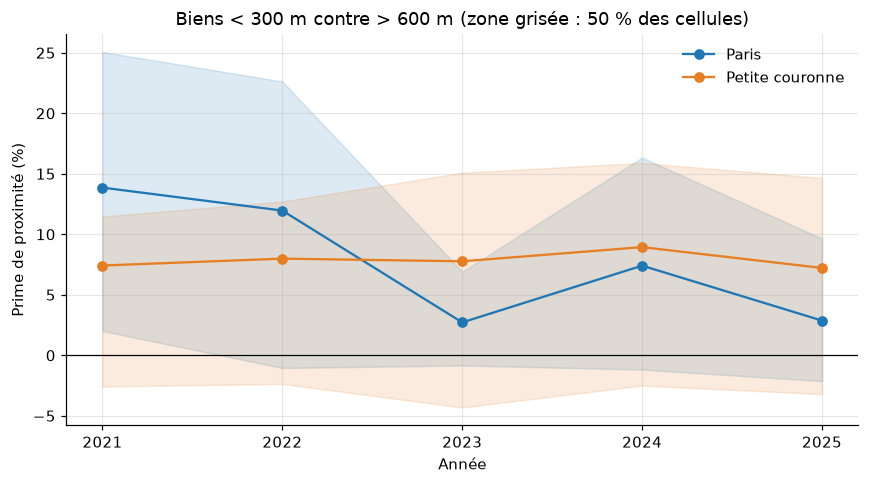

In [7]:
display(A.prime_stratifiee(d))
par_annee = A.sauver(A.prime_stratifiee(d, par_annee=True), "prime_stratifiee_par_annee.csv", index=False)
V.prime_stratifiee_annee(par_annee)
par_annee

En petite couronne, les biens situés à moins de 300 m d'une station se vendent en moyenne environ 7 à 9 % plus cher que ceux situés à plus de 600 m, à commune, année et classe de surface comparables. Cette prime est très stable de 2021 à 2025 (entre 7 % et 9 % environ).

À Paris, la prime est plus variable : environ 14 % en 2021 et 12 % en 2022, puis environ 3 % en 2023, 7,5 % en 2024 et 3 % en 2025. Elle paraît donc plus faible sur les dernières années, mais cette évolution reste à prendre avec prudence.

La dispersion est importante : la zone grisée (la moitié centrale des cellules) est large dans les deux zones et inclut zéro pour la plupart des années. Autrement dit, la prime moyenne cache des situations très différentes d'une cellule à l'autre, avec des communes ou des classes de surface où l'écart est nul, voire négatif. À Paris, la dispersion est particulièrement grande en 2021 et 2022.

Ces résultats sont cohérents avec les sections précédentes : le prix est à peu près stable à moins de 400 m et baisse surtout au-delà de 600 m, ce qui explique une prime proche/loin même quand il n'y a pas de gradient près des stations.

## 6. Robustesse

Le résultat tient-il quand on change les seuils de proximité, le nombre minimal de ventes par groupe, ou qu'on garde les prix extrêmes ?

In [8]:
A.sauver(A.robustesse_prime(df), "robustesse_prime_stratifiee.csv", index=False)

,specification,zone,prime_%,mediane_cellules_%,q25_%,q75_%,part_cellules_positives_%,n_cellules
0,"référence : <300 m vs ≥600 m, 10 ventes min.",Paris,8.90,6.91,-1.21,15.40,69.23,39.00
1,"référence : <300 m vs ≥600 m, 10 ventes min.",Petite couronne,7.81,4.89,-2.90,13.99,66.15,582.00
2,<200 m vs ≥500 m,Paris,4.57,3.84,0.40,10.14,77.60,125.00
3,<200 m vs ≥500 m,Petite couronne,5.42,5.04,-2.77,12.08,66.86,344.00
4,<400 m vs ≥800 m,Petite couronne,8.58,4.82,-2.98,15.83,66.84,570.00
5,20 ventes min. par groupe,Paris,3.07,-4.21,-7.36,12.07,40.00,5.00
6,20 ventes min. par groupe,Petite couronne,8.24,5.44,-0.69,12.82,71.43,322.00
7,5 ventes min. par groupe,Paris,8.55,7.07,-0.78,14.16,72.22,90.00
8,5 ventes min. par groupe,Petite couronne,7.55,4.54,-3.81,14.89,64.58,895.00
9,sans écarter les prix extrêmes,Paris,9.17,6.88,-0.91,17.96,70.00,40.00


En petite couronne, la prime reste positive et du même ordre de grandeur quelle que soit la spécification : entre 5,4 % et 8,6 % (moyenne pondérée), avec 64 % à 71 % de cellules où l'écart est positif et plusieurs centaines de cellules (322 à 895). Elle est un peu plus faible quand on compare les biens à moins de 200 m à ceux à plus de 500 m (5,4 %). Garder ou écarter les prix extrêmes ne change presque rien (7,8 % contre 7,6 à 7,8 %).

À Paris, le résultat est positif dans presque toutes les spécifications (de 4,6 % à 9,2 %), mais il repose sur très peu de cellules : 39 dans la spécification de référence, contre 582 en petite couronne. Avec 20 ventes minimum par groupe, il n'en reste que 5 et la prime tombe à 3,1 % avec une médiane négative (−4,2 %). Le seuil 400 m contre 800 m ne donne aucun résultat à Paris, faute de ventes éloignées. Le résultat parisien est donc fragile : on peut dire que le signe est le plus souvent positif, mais pas préciser sa taille.

Partout, la moyenne est supérieure à la médiane des cellules (par exemple 7,8 % contre 4,9 % en petite couronne), et la moitié centrale des cellules inclut zéro : quelques cellules avec de gros écarts positifs tirent la moyenne vers le haut. Le message le plus fiable est donc que les biens proches se vendent plus cher dans environ deux cellules sur trois, avec un écart typique de l'ordre de 5 % en petite couronne.

## 7. Étude de cas : les prolongements des lignes 11 et 14 (juin 2024)

En juin 2024, la ligne 11 a été prolongée jusqu'à Rosny-Bois-Perrier et la ligne 14 jusqu'à Saint-Denis-Pleyel et l'aéroport d'Orly. C'est l'occasion d'observer ce qui se passe quand un quartier **gagne** une station, en suivant les mêmes quartiers avant et après l'ouverture.

Deux groupes de ventes, définis par leur position (et non par leur date) :

- **desservi** : à moins de 600 m d'une nouvelle station et à plus de 800 m de toute station avant l'ouverture. Les stations implantées là où une autre ligne passait déjà (Maison Blanche, Saint-Denis-Pleyel, Rosny-Bois-Perrier) en sont donc exclues ;
- **témoin** : ventes des mêmes communes, situées à plus de 1,2 km de toute nouvelle station.

Les deux groupes n'ont pas le même niveau de prix. On compare donc leur **évolution** : prix médian au m² en base 100 en 2021.

,n Desservi en 2024,prix_median Desservi en 2024,indice Desservi en 2024,n Témoin,prix_median Témoin,indice Témoin,ecart_indices
annee,,,,,,,
2021,530,"4,416.00",100.00,2278,"5,295.00",100.00,0.00
2022,494,"4,667.00",105.70,2400,"5,470.00",103.30,2.40
2023,370,"4,763.00",107.90,1789,"5,171.00",97.70,10.20
2024,366,"4,175.00",94.50,1495,"4,804.00",90.70,3.80
2025,427,"4,808.00",108.90,1780,"4,900.00",92.50,16.40


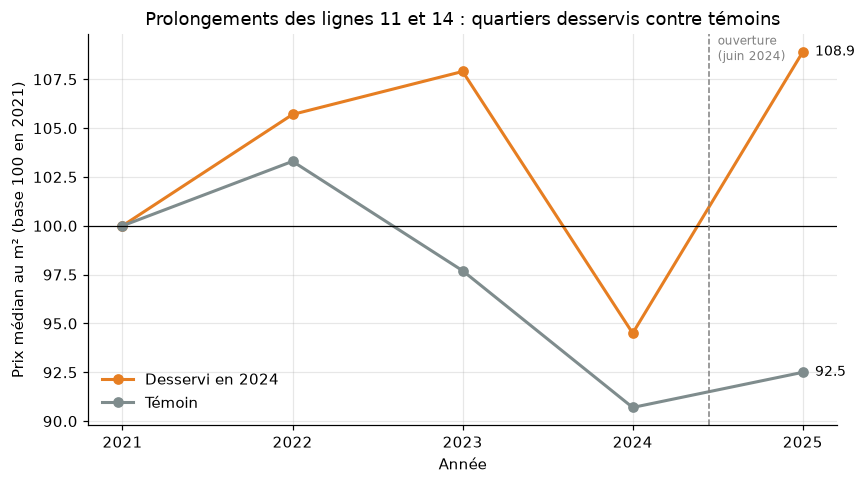

In [9]:
d_prol = A.distances_prolongements(df)
g_prol = A.groupes_prolongements(d_prol)
prol = A.sauver(A.evolution_prolongements(g_prol), "prolongements_l11_l14.csv")
V.evolution_prolongements(prol)
prol

In [10]:
specs = [(600, 800, 1200), (400, 800, 1200), (800, 800, 1200), (600, 600, 1200), (600, 800, 1500)]
lignes = []
for rayon, avant, loin in specs:
    t = A.evolution_prolongements(A.groupes_prolongements(d_prol, rayon, avant, loin))
    lignes.append({"rayon_m": rayon, "sans_station_avant_m": avant, "temoin_au_dela_m": loin,
                   "ventes_desservies": int(t["n Desservi en 2024"].sum()),
                   **{f"ecart_{a}": t.loc[a, "ecart_indices"] for a in t.index}})
A.sauver(pd.DataFrame(lignes), "robustesse_prolongements.csv", index=False)

,rayon_m,sans_station_avant_m,temoin_au_dela_m,ventes_desservies,ecart_2021,ecart_2022,ecart_2023,ecart_2024,ecart_2025
0,600,800,1200,2187,0.00,2.40,10.20,3.80,16.40
1,400,800,1200,1333,0.00,-1.60,9.80,3.20,12.50
2,800,800,1200,2888,0.00,4.50,9.70,6.30,15.50
3,600,600,1200,2411,0.00,3.60,10.90,3.60,14.50
4,600,800,1500,2187,0.00,2.30,8.90,3.20,15.60


De 2021 à 2025, le prix médian des quartiers desservis augmente d'environ 9 % (indice 108,9), alors que celui des quartiers témoins des mêmes communes baisse d'environ 7 % (indice 92,5). L'écart atteint donc **environ 16 points** en 2025. Il reste compris entre 12 et 16 points quand on modifie les seuils de distance.

Deux observations :

- **l'écart se creuse dès 2023, avant l'ouverture** (+10 points). Cela correspond à une anticipation : les chantiers et la date de mise en service étaient connus depuis plusieurs années, et les acheteurs ont pu intégrer le futur métro dans le prix ;
- **2024 est une année de transition** : elle mélange des ventes conclues avant et après juin, ce qui explique en partie le creux observé pour les deux groupes, dans un marché en baisse.

Limites : environ 400 ventes par an seulement dans le groupe desservi, ce qui rend les médianes annuelles assez volatiles. Il s'agit d'une comparaison descriptive : les quartiers desservis peuvent aussi avoir changé pour d'autres raisons (rénovation urbaine, nouveaux programmes), et ce résultat ne mesure pas un effet causal.

## 8. Conclusion et limites

À commune, année et taille de logement comparables, les appartements proches d'une station se vendent un peu plus cher que les appartements éloignés, mais l'écart est modeste et concentré sur certaines distances.

- Pris ensemble, le prix et la distance sont fortement corrélés (Spearman autour de −0,56 à −0,60), mais cette corrélation vient surtout de la différence entre Paris et la petite couronne. Une fois le prix exprimé relativement à sa commune, elle tombe presque à zéro (entre 0 et −0,06) : à l'intérieur d'une commune, la distance explique très peu les écarts de prix.
- Le prix relatif est à peu près stable jusqu'à 400 m et diminue ensuite, surtout au-delà de 600 m (environ −6,5 % à 600-1000 m à Paris et −3 % en petite couronne par rapport à la tranche 200-400 m). La distance la plus valorisée se situe entre 100 et 400 m.
- En petite couronne, on observe aussi une décote à moins de 100 m (environ −3,5 % par rapport à 200-400 m), compatible avec des nuisances de proximité. Elle reste à confirmer, car peu de ventes se situent si près d'une station. À Paris, elle est très faible (environ −1 %).
- La prime des biens à moins de 300 m par rapport à ceux à plus de 600 m est de l'ordre de 5 à 8 % en petite couronne, stable de 2021 à 2025 et robuste aux seuils retenus. À Paris, le signe est le plus souvent positif, mais le résultat repose sur trop peu de cellules pour être chiffré.

**Ce que disent nos hypothèses.** L'hypothèse H1 (le prix baisse avec l'éloignement) est confirmée en petite couronne et au-delà de 600 m, mais pas à courte distance. L'hypothèse H2 (décote à très courte distance) est suggérée en petite couronne, pas à Paris. L'hypothèse H3 (prime plus marquée en petite couronne) est plausible, mais on ne peut pas la tester proprement faute de cellules parisiennes éloignées des stations.

**Limites.**
- Ces calculs décrivent des associations, pas des effets causaux : les stations sont implantées dans des zones déjà denses et recherchées.
- Une cellule rapproche des biens de même commune, de même année et de même classe de surface, mais pas de même étage, état ou quartier : le DVF ne contient pas ces informations. L'échelle de la commune est large, surtout en petite couronne.
- Les coordonnées sont celles du centre de la parcelle, ce qui ajoute du bruit aux très courtes distances (moins de 100 m).
- À Paris, presque aucune vente ne se situe à plus de 800 m d'une station : les comparaisons proche/loin reposent sur peu de cellules et sont fragiles.
- La distance est mesurée à vol d'oiseau, pas en temps de marche, et la qualité du service (fréquence, lignes, fréquentation) n'est pas prise en compte.
- Les moyennes pondérées des écarts sont plus élevées que les médianes des cellules : quelques cellules avec de gros écarts positifs tirent les moyennes vers le haut, et la moitié centrale des cellules inclut zéro. L'effet est donc hétérogène d'une commune à l'autre.
- Les parcs, les axes routiers et les équipements de proximité ne sont pas pris en compte.